# **MÓDULO 14 - Exercício**
# Pré Processamento dos Dados - A primeira etapa Pré Modelagem

Para nossa atividade usaremos uma base de churn também, porém essa base não diz respeito a serviços bancários e sim serviços de internet, telefone e tv - Telecomunicação.

Vamos realizar aqui as etapas de limpeza e tratamento de dados vistos durante a aula, porém aplicados a essa base nova.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Base original (no Colab, enviar o arquivo para a pasta dados/ antes)
df = pd.read_csv("dados/CHURN_TELECON_MOD08_TAREFA.csv", delimiter=';')

df.head(10)

,customerID,Genero,Idoso,Casado,Dependents,Tempo_como_Cliente,PhoneService,Servico_Internet,Servico_Seguranca,Suporte_Tecnico,StreamingTV,Tipo_Contrato,PaymentMethod,Pagamento_Mensal,Total_Pago,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,DSL,No,No,No,Month-to-month,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,DSL,Yes,No,No,One year,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,DSL,Yes,No,No,Month-to-month,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,DSL,Yes,Yes,No,One year,Bank transfer (automatic),NaN,1840.75,No
4,9237-HQITU,NaN,0,No,No,2,Yes,Fiber optic,No,No,No,Month-to-month,Electronic check,NaN,151.65,Yes
5,9305-CDSKC,NaN,0,No,No,8,Yes,Fiber optic,No,No,Yes,Month-to-month,Electronic check,NaN,820.50,NaN
6,1452-KIOVK,NaN,0,No,Yes,22,Yes,Fiber optic,No,No,Yes,Month-to-month,Credit card (automatic),NaN,1949.40,NaN
7,6713-OKOMC,NaN,0,No,No,10,No,DSL,Yes,No,No,Month-to-month,Mailed check,NaN,301.90,NaN
8,7892-POOKP,NaN,0,Yes,No,28,Yes,Fiber optic,No,Yes,Yes,Month-to-month,Electronic check,NaN,3046.05,NaN
9,6388-TABGU,NaN,0,No,Yes,62,Yes,dsl,Yes,No,No,One year,Bank transfer (automatic),NaN,3487.95,NaN


Legenda dos dados:

*   **CustomerID** : Esse é o ID único de cada cliente nosso da rede de produtos de telecomunicação.
*   **Genero** : O genero dos nossos clientes.
*   **Idoso** : Se nosso cliente tem acima de 60 anos ou não. (Sim = 1 | Não = 0)
*   **Casado** : Se nosso cliente é casado ou não.
*   **Dependents** : Se cliente tem dependentes.
*   **Tempo_como_Cliente** : Tempo em meses que nosso cliente está com a nossa empresa.
*   **PhoneService** : Se ele contratou serviço telefônico com a nossa empresa.
*   **Servico_Internet** : Qual o tipo de serviço de internet contratado.
*   **Servico_Seguranca** : Se ele contratou serviço de segurança com a nossa empresa.
*   **Suporte_Tecnico** : Se já acionou o suporte técnico.
*   **StreamingTV** : Se ele contratou serviço de streaming para TV.
*   **Tipo_Contrato** : Qual o tipo de contrato dos nossos clientes, se era mensal, anual etc.
*   **PaymentMethod** : Forma de Pagamento.
*   **Pagamento_Mensal** : Quanto o cliente pagava mensalmente.
*   **Total_Pago** : Total já pago pelo cliente para nossa companhia.
*   **Churn** : Nossa coluna mais importante, se nosso cliente nos abandonou ou não.

---
# 1 - Carregue a base, verifique se os tipos de dados estão de acordo com cada coluna e caso não estejam realize a transformação dos tipos de dados.

In [3]:
# Verificando os tipos de dados atuais
print('Tipos de dados originais:')
print(df.dtypes)
print()
print('Shape do DataFrame:', df.shape)

Tipos de dados originais:
customerID                str
Genero                    str
Idoso                   int64
Casado                    str
Dependents                str
Tempo_como_Cliente      int64
PhoneService              str
Servico_Internet          str
Servico_Seguranca         str
Suporte_Tecnico           str
StreamingTV               str
Tipo_Contrato             str
PaymentMethod             str
Pagamento_Mensal      float64
Total_Pago            float64
Churn                     str
dtype: object

Shape do DataFrame: (2500, 16)


In [4]:
# Visualizando os primeiros registros para entender o conteúdo
df.head()

,customerID,Genero,Idoso,Casado,Dependents,Tempo_como_Cliente,PhoneService,Servico_Internet,Servico_Seguranca,Suporte_Tecnico,StreamingTV,Tipo_Contrato,PaymentMethod,Pagamento_Mensal,Total_Pago,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,DSL,No,No,No,Month-to-month,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,DSL,Yes,No,No,One year,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,DSL,Yes,No,No,Month-to-month,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,DSL,Yes,Yes,No,One year,Bank transfer (automatic),NaN,1840.75,No
4,9237-HQITU,NaN,0,No,No,2,Yes,Fiber optic,No,No,No,Month-to-month,Electronic check,NaN,151.65,Yes


In [5]:
# Transformação dos tipos de dados
# As colunas Pagamento_Mensal e Total_Pago devem ser numéricas (float)
# O parâmetro errors='coerce' transforma valores inválidos em NaN, sem quebrar a execução
df['Pagamento_Mensal'] = pd.to_numeric(df['Pagamento_Mensal'], errors='coerce')
df['Total_Pago']       = pd.to_numeric(df['Total_Pago'], errors='coerce')

print('Tipos de dados após transformação:')
print(df.dtypes)

Tipos de dados após transformação:
customerID                str
Genero                    str
Idoso                   int64
Casado                    str
Dependents                str
Tempo_como_Cliente      int64
PhoneService              str
Servico_Internet          str
Servico_Seguranca         str
Suporte_Tecnico           str
StreamingTV               str
Tipo_Contrato             str
PaymentMethod             str
Pagamento_Mensal      float64
Total_Pago            float64
Churn                     str
dtype: object


**Análise — Questão 1:**

Ao inspecionar os tipos de dados com `dtypes`, identificamos que as colunas `Pagamento_Mensal` e `Total_Pago` estavam originalmente lidas como `object` (string). O correto é que sejam numéricas (`float64`), pois representam valores monetários. A conversão foi feita com `pd.to_numeric(..., errors='coerce')`, garantindo que eventuais valores inválidos sejam tratados como `NaN` em vez de lançar um erro.

---
# 2 - Tratamento de Dados Faltantes

## A) Verifique se temos colunas com dados faltantes e traga a % dos dados faltantes por coluna.

In [6]:
# Calculando a quantidade e percentual de valores nulos por coluna
missing_count = df.isnull().sum()
missing_pct   = (missing_count / len(df)) * 100

missing_df = pd.DataFrame({
    'Valores Faltantes': missing_count,
    '% Faltante': missing_pct.round(2)
})

# Exibindo apenas as colunas que possuem ao menos 1 valor faltante
print(missing_df[missing_df['Valores Faltantes'] > 0])

                  Valores Faltantes  % Faltante
Genero                           12        0.48
PhoneService                   1482       59.28
Pagamento_Mensal                325       13.00
Churn                             5        0.20


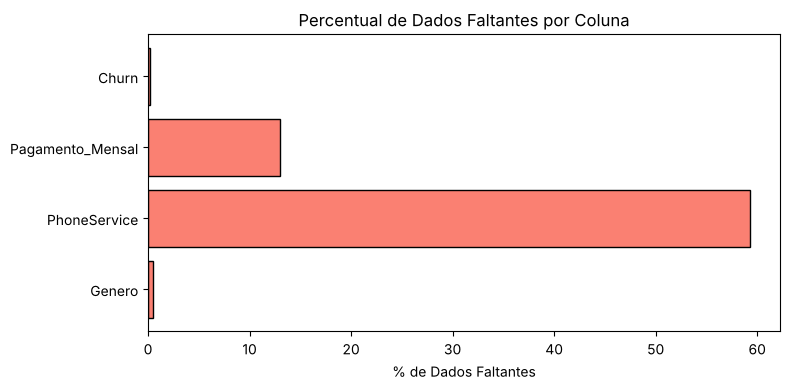

In [7]:
# Visualizando graficamente o percentual de dados faltantes
colunas_com_nulos = missing_df[missing_df['Valores Faltantes'] > 0]

plt.figure(figsize=(8, 4))
plt.barh(colunas_com_nulos.index, colunas_com_nulos['% Faltante'], color='salmon', edgecolor='black')
plt.xlabel('% de Dados Faltantes')
plt.title('Percentual de Dados Faltantes por Coluna')
plt.tight_layout()
plt.show()

**Resultado — Questão 2A:**

Encontramos dados faltantes em **4 colunas**:

| Coluna | Valores Faltantes | % Faltante |
|---|---|---|
| `Genero` | 12 | 0,48% |
| `PhoneService` | 1.482 | 59,28% |
| `Pagamento_Mensal` | 325 | 13,00% |
| `Churn` | 5 | 0,20% |

## B) Exclua as linhas das colunas onde esse método é o ideal. Justifique.

In [8]:
print('Shape antes da exclusão:', df.shape)

# Excluindo as linhas onde a coluna 'Churn' é nula
df = df.dropna(subset=['Churn'])

print('Shape após exclusão das linhas com Churn nulo:', df.shape)
print('Linhas removidas:', 2500 - len(df))

Shape antes da exclusão: (2500, 16)
Shape após exclusão das linhas com Churn nulo: (2495, 16)
Linhas removidas: 5


**Justificativa — Questão 2B:**

A coluna **`Churn`** é nossa **variável-alvo** (o que queremos prever). Registros sem essa informação não têm utilidade para o modelo, pois não podemos saber se o cliente saiu ou não. Como são apenas **5 linhas (0,20%)** do total, a exclusão não representa perda significativa de dados.

> As demais colunas com dados faltantes (`Genero`, `PhoneService`, `Pagamento_Mensal`) serão tratadas no item C, pois o volume de dados ou o tipo da variável permitem imputação.

## C) Substitua pela média, mediana ou moda. Justifique.

Distribuição de Genero:
Genero
Male      1265
Female    1212
M            4
f            4
F            3
Name: count, dtype: int64


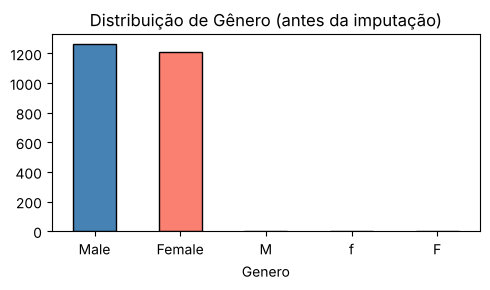


Moda de Genero: Male
Nulos em Genero após imputação: 0


In [9]:
# --- Variável Categórica: Genero (0,48% faltante) ---
print('Distribuição de Genero:')
print(df['Genero'].value_counts())

plt.figure(figsize=(5, 3))
df['Genero'].value_counts().plot(kind='bar', color=['steelblue', 'salmon', 'green', 'purple'], edgecolor='black')
plt.title('Distribuição de Gênero (antes da imputação)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

moda_genero = df['Genero'].mode()[0]
print(f'\nModa de Genero: {moda_genero}')
df['Genero'] = df['Genero'].fillna(moda_genero)
print('Nulos em Genero após imputação:', df['Genero'].isnull().sum())

Distribuição de PhoneService:
PhoneService
Yes    927
No      86
Name: count, dtype: int64


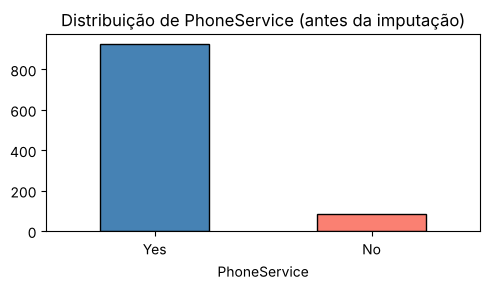


Moda de PhoneService: Yes
Nulos em PhoneService após imputação: 0


In [10]:
# --- Variável Categórica: PhoneService (59,28% faltante) ---
print('Distribuição de PhoneService:')
print(df['PhoneService'].value_counts())

plt.figure(figsize=(5, 3))
df['PhoneService'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'], edgecolor='black')
plt.title('Distribuição de PhoneService (antes da imputação)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

moda_phone = df['PhoneService'].mode()[0]
print(f'\nModa de PhoneService: {moda_phone}')
df['PhoneService'] = df['PhoneService'].fillna(moda_phone)
print('Nulos em PhoneService após imputação:', df['PhoneService'].isnull().sum())

Estatísticas de Pagamento_Mensal:
count    2175.000000
mean       65.607563
std        29.931520
min        18.400000
25%        39.500000
50%        71.450000
75%        90.250000
max       118.650000
Name: Pagamento_Mensal, dtype: float64

Skewness (assimetria): -0.2800
Média:   65.61
Mediana: 71.45


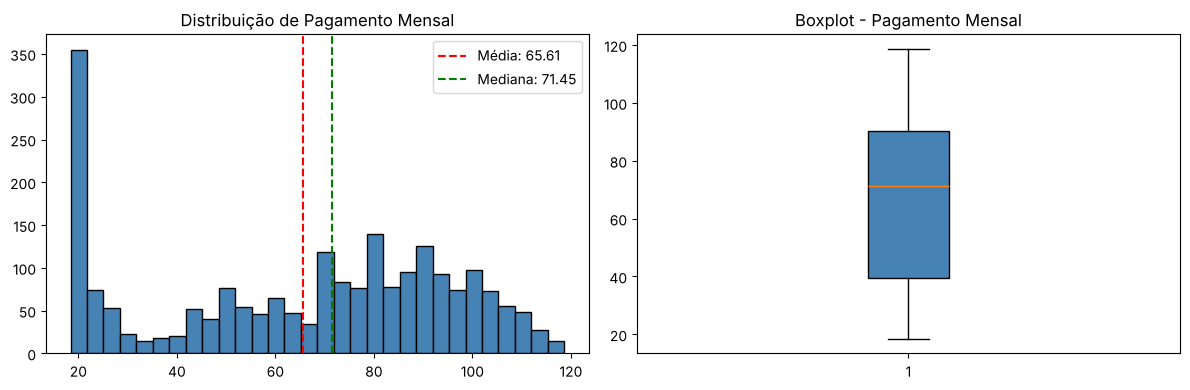


Nulos em Pagamento_Mensal após imputação pela mediana (71.45): 0


In [11]:
# --- Variável Numérica: Pagamento_Mensal (13% faltante) ---
print('Estatísticas de Pagamento_Mensal:')
print(df['Pagamento_Mensal'].describe())
print(f"\nSkewness (assimetria): {df['Pagamento_Mensal'].skew():.4f}")
print(f"Média:   {df['Pagamento_Mensal'].mean():.2f}")
print(f"Mediana: {df['Pagamento_Mensal'].median():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
axes[0].hist(df['Pagamento_Mensal'].dropna(), bins=30, color='steelblue', edgecolor='black')
axes[0].axvline(df['Pagamento_Mensal'].mean(),   color='red',    linestyle='--', label=f"Média: {df['Pagamento_Mensal'].mean():.2f}")
axes[0].axvline(df['Pagamento_Mensal'].median(), color='green',  linestyle='--', label=f"Mediana: {df['Pagamento_Mensal'].median():.2f}")
axes[0].set_title('Distribuição de Pagamento Mensal')
axes[0].legend()

# Boxplot
axes[1].boxplot(df['Pagamento_Mensal'].dropna(), patch_artist=True,
                boxprops=dict(facecolor='steelblue', color='black'))
axes[1].set_title('Boxplot - Pagamento Mensal')

plt.tight_layout()
plt.show()

mediana_pagamento = df['Pagamento_Mensal'].median()
df['Pagamento_Mensal'] = df['Pagamento_Mensal'].fillna(mediana_pagamento)
print(f'\nNulos em Pagamento_Mensal após imputação pela mediana ({mediana_pagamento}):', df['Pagamento_Mensal'].isnull().sum())

In [12]:
# Verificação final: nenhum valor nulo deve restar
print('Valores nulos restantes por coluna:')
print(df.isnull().sum())
print(f'\nTotal de nulos: {df.isnull().sum().sum()}')

Valores nulos restantes por coluna:
customerID            0
Genero                0
Idoso                 0
Casado                0
Dependents            0
Tempo_como_Cliente    0
PhoneService          0
Servico_Internet      0
Servico_Seguranca     0
Suporte_Tecnico       0
StreamingTV           0
Tipo_Contrato         0
PaymentMethod         0
Pagamento_Mensal      0
Total_Pago            0
Churn                 0
dtype: int64

Total de nulos: 0


**Justificativas — Questão 2C:**

**`Genero` (0,48% faltante — categórica):**  
Por se tratar de uma variável categórica, não faz sentido usar média ou mediana. Utilizamos a **moda** (`Male`), que é o valor mais frequente. Poderíamos também excluir as 12 linhas, mas optamos pela imputação para não perder nenhum registro desnecessariamente.

**`PhoneService` (59,28% faltante — categórica):**  
Excluir as linhas não é uma opção viável — perderíamos mais da metade da base. O gráfico de barras mostra clara dominância do valor `Yes` (≈ 91% dos registros não nulos), portanto a **moda (`Yes`)** é a escolha mais representativa para a imputação.

**`Pagamento_Mensal` (13% faltante — numérica):**  
O histograma e o boxplot revelam que a distribuição é aproximadamente simétrica (skewness ≈ -0.28). Em distribuições próximas da normal, média e mediana são parecidas, mas optamos pela **mediana** por ser mais robusta a eventuais valores extremos e por ser ligeiramente mais segura em casos de leve assimetria.

---
# 3 - Verifique e corrija valores digitados incorretamente, inconsistências de maiúsculas/minúsculas ou grafias diferentes para o mesmo valor.

In [13]:
# Inspecionando valores únicos de colunas categóricas para identificar inconsistências
colunas_categoricas = ['Genero', 'Casado', 'Dependents', 'PhoneService',
                       'Servico_Internet', 'Servico_Seguranca', 'Suporte_Tecnico',
                       'StreamingTV', 'Tipo_Contrato', 'PaymentMethod', 'Churn']

for col in colunas_categoricas:
    print(f'{col}: {sorted(df[col].dropna().unique())}')

Genero: ['F', 'Female', 'M', 'Male', 'f']
Casado: ['No', 'Yes']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
Servico_Internet: ['DSL', 'Fiber optic', 'No', 'dsl']
Servico_Seguranca: ['No', 'No internet service', 'Yes']
Suporte_Tecnico: ['No', 'No internet service', 'Yes']
StreamingTV: ['No', 'No internet service', 'Yes']
Tipo_Contrato: ['Month-to-month', 'One year', 'Two year']
PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn: ['No', 'Yes']


In [14]:
# --- Correção 1: Coluna 'Genero' ---
# Problema: 'F' e 'f' deveriam ser 'Female', 'M' deveria ser 'Male'
print('Genero ANTES:', df['Genero'].value_counts().to_dict())

df['Genero'] = df['Genero'].replace({
    'F': 'Female',
    'f': 'Female',
    'M': 'Male'
})

print('Genero DEPOIS:', df['Genero'].value_counts().to_dict())

Genero ANTES: {'Male': 1272, 'Female': 1212, 'M': 4, 'f': 4, 'F': 3}
Genero DEPOIS: {'Male': 1276, 'Female': 1219}


In [15]:
# --- Correção 2: Coluna 'Servico_Internet' ---
# Problema: 'dsl' deveria ser 'DSL' (mesclagem por capitalização diferente)
print('Servico_Internet ANTES:', df['Servico_Internet'].value_counts().to_dict())

df['Servico_Internet'] = df['Servico_Internet'].replace({'dsl': 'DSL'})

print('Servico_Internet DEPOIS:', df['Servico_Internet'].value_counts().to_dict())

Servico_Internet ANTES: {'Fiber optic': 1124, 'DSL': 835, 'No': 528, 'dsl': 8}
Servico_Internet DEPOIS: {'Fiber optic': 1124, 'DSL': 843, 'No': 528}


In [16]:
# Confirmação: verificando novamente todos os valores únicos após correção
print('=== Verificação final dos valores únicos ===')
for col in colunas_categoricas:
    print(f'{col}: {sorted(df[col].dropna().unique())}')

=== Verificação final dos valores únicos ===
Genero: ['Female', 'Male']
Casado: ['No', 'Yes']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
Servico_Internet: ['DSL', 'Fiber optic', 'No']
Servico_Seguranca: ['No', 'No internet service', 'Yes']
Suporte_Tecnico: ['No', 'No internet service', 'Yes']
StreamingTV: ['No', 'No internet service', 'Yes']
Tipo_Contrato: ['Month-to-month', 'One year', 'Two year']
PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn: ['No', 'Yes']


**Análise — Questão 3:**

Foram identificadas e corrigidas **2 inconsistências**:

1. **`Genero`**: Os valores `'F'` e `'f'` representavam `'Female'`, e `'M'` representava `'Male'`. Foram mapeados para os valores padronizados.
2. **`Servico_Internet`**: O valor `'dsl'` (minúsculo) é o mesmo que `'DSL'`. Foi padronizado para `'DSL'`.

As demais colunas categóricas não apresentaram inconsistências de grafia ou capitalização.

---
# [EXTRA] 4 - Renomeação de colunas para manter padrão em português

In [17]:
print('Colunas ANTES da renomeação:')
print(df.columns.tolist())

df.rename(columns={
    'customerID'       : 'ID_Cliente',
    'Dependents'       : 'Dependentes',
    'PhoneService'     : 'Servico_Telefone',
    'StreamingTV'      : 'Streaming_TV',
    'PaymentMethod'    : 'Forma_Pagamento'
}, inplace=True)

print('\nColunas APÓS a renomeação:')
print(df.columns.tolist())

Colunas ANTES da renomeação:
['customerID', 'Genero', 'Idoso', 'Casado', 'Dependents', 'Tempo_como_Cliente', 'PhoneService', 'Servico_Internet', 'Servico_Seguranca', 'Suporte_Tecnico', 'StreamingTV', 'Tipo_Contrato', 'PaymentMethod', 'Pagamento_Mensal', 'Total_Pago', 'Churn']

Colunas APÓS a renomeação:
['ID_Cliente', 'Genero', 'Idoso', 'Casado', 'Dependentes', 'Tempo_como_Cliente', 'Servico_Telefone', 'Servico_Internet', 'Servico_Seguranca', 'Suporte_Tecnico', 'Streaming_TV', 'Tipo_Contrato', 'Forma_Pagamento', 'Pagamento_Mensal', 'Total_Pago', 'Churn']


In [18]:
# Visualização final do DataFrame tratado
print('Shape final:', df.shape)
print()
df.head(10)

Shape final: (2495, 16)



,ID_Cliente,Genero,Idoso,Casado,Dependentes,Tempo_como_Cliente,Servico_Telefone,Servico_Internet,Servico_Seguranca,Suporte_Tecnico,Streaming_TV,Tipo_Contrato,Forma_Pagamento,Pagamento_Mensal,Total_Pago,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,DSL,No,No,No,Month-to-month,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,DSL,Yes,No,No,One year,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,DSL,Yes,No,No,Month-to-month,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,DSL,Yes,Yes,No,One year,Bank transfer (automatic),71.45,1840.75,No
4,9237-HQITU,Male,0,No,No,2,Yes,Fiber optic,No,No,No,Month-to-month,Electronic check,71.45,151.65,Yes
10,9763-GRSKD,Male,0,Yes,Yes,13,Yes,DSL,Yes,No,No,Month-to-month,Mailed check,71.45,587.45,No
11,7469-LKBCI,Male,0,No,No,16,Yes,No,No internet service,No internet service,No internet service,Two year,Credit card (automatic),71.45,326.80,No
12,8091-TTVAX,Male,0,Yes,No,58,Yes,Fiber optic,No,No,Yes,One year,Credit card (automatic),71.45,5681.10,No
13,0280-XJGEX,Male,0,No,No,49,Yes,Fiber optic,No,No,Yes,Month-to-month,Bank transfer (automatic),71.45,5036.30,Yes
14,5129-JLPIS,Male,0,No,No,25,Yes,Fiber optic,Yes,Yes,Yes,Month-to-month,Electronic check,71.45,2686.05,No


**Análise — Questão 4 (Extra):**

As colunas que estavam em inglês (`customerID`, `Dependents`, `PhoneService`, `StreamingTV`, `PaymentMethod`) foram renomeadas para o português, mantendo a consistência com as demais colunas já nomeadas em português. O DataFrame final possui:
- **2.495 linhas** (removidas as 5 linhas com `Churn` nulo)
- **16 colunas** completamente tratadas e padronizadas
- **0 valores nulos**

---
# 5 - Exportação da base tratada

A base tratada é salva em `dados/data_preprocessed.csv` para ser usada na análise exploratória do [Módulo 15](../modulo-15-eda/).

In [19]:
# Salvando a base tratada para a próxima etapa (Módulo 15)
df.to_csv('dados/data_preprocessed.csv', index=False)
print('Base salva em dados/data_preprocessed.csv:', df.shape)

Base salva em dados/data_preprocessed.csv: (2495, 16)
